# Part II — Different trip rhythms within one bike-share system
## by Noufal

## Investigation Overview

This report communicates four descriptive findings from the preceding Ford GoBike exploration. Its audience is a bike-share service analyst comparing recorded trip patterns, not estimating causal effects or counting unique customers.

## Dataset Overview and Executive Summary

The official Bay Wheels February 2019 archive contains 183,412 trips and 14 raw fields. All trips pass the essential validity checks; the nine-column analytical dataset preserves long durations and does not remove trips for missing optional station labels. Source URL, retrieval timestamp and checksums are included with the raw data.

Four questions organize the report:
1. Who accounts for most recorded trips? Subscriber trips represent 89.2% of the total.
2. Do weekday timing patterns differ after accounting for group size? Within-group profiles retain distinct timing, with Subscriber morning/evening peaks.
3. How does typical duration differ? Customer trips have a 13.2-minute median versus 8.2 minutes for Subscriber trips.
4. Is the weekday–weekend volume gap merely unequal calendar exposure? Subscriber daily volume still falls substantially on weekends; Customer daily volume is similar.

These are the same findings summarized in Part I. Four polished figures are selected from 12 exploratory figures, fewer than half the exploratory count.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
from bike_analysis import prepare_trips, load_clean, summarize, hourly_rates
from bike_plots import exploratory_figure, explanatory_figure

ROOT = Path.cwd()
RAW = ROOT / 'data/raw'
CLEAN = ROOT / 'data/cleaned'
FIGURES = ROOT / 'figures'
EVIDENCE = ROOT / 'evidence'
for folder in (CLEAN, FIGURES, EVIDENCE):
    folder.mkdir(parents=True, exist_ok=True)

def show_chart(fig, name):
    """Embed the saved PNG explicitly so headless execution preserves visible evidence."""
    path = FIGURES / (name + '.png')
    fig.savefig(path, dpi=140, bbox_inches='tight')
    display(Image(filename=str(path)))
    plt.close(fig)

print('pandas', pd.__version__, '| NumPy', np.__version__, '| Seaborn', sns.__version__)

pandas 2.3.3 | NumPy 2.5.4 | Seaborn 0.13.2


In [2]:
# Load the same stored analytical table rather than applying a different cleaning rule.
trips = load_clean(CLEAN / 'february_2019_trips.csv')
saved_summary = json.loads((EVIDENCE / 'summary.json').read_text())
summary = summarize(trips)
assert summary == saved_summary
print('Verified shared analysis population:', len(trips), 'trips; February 2019')
print('Median durations (minutes):', summary['subscriber_median_minutes'], summary['customer_median_minutes'])

Verified shared analysis population: 183412 trips; February 2019
Median durations (minutes): 8.166666666666666 13.2


### Question — Who accounts for most recorded trips?

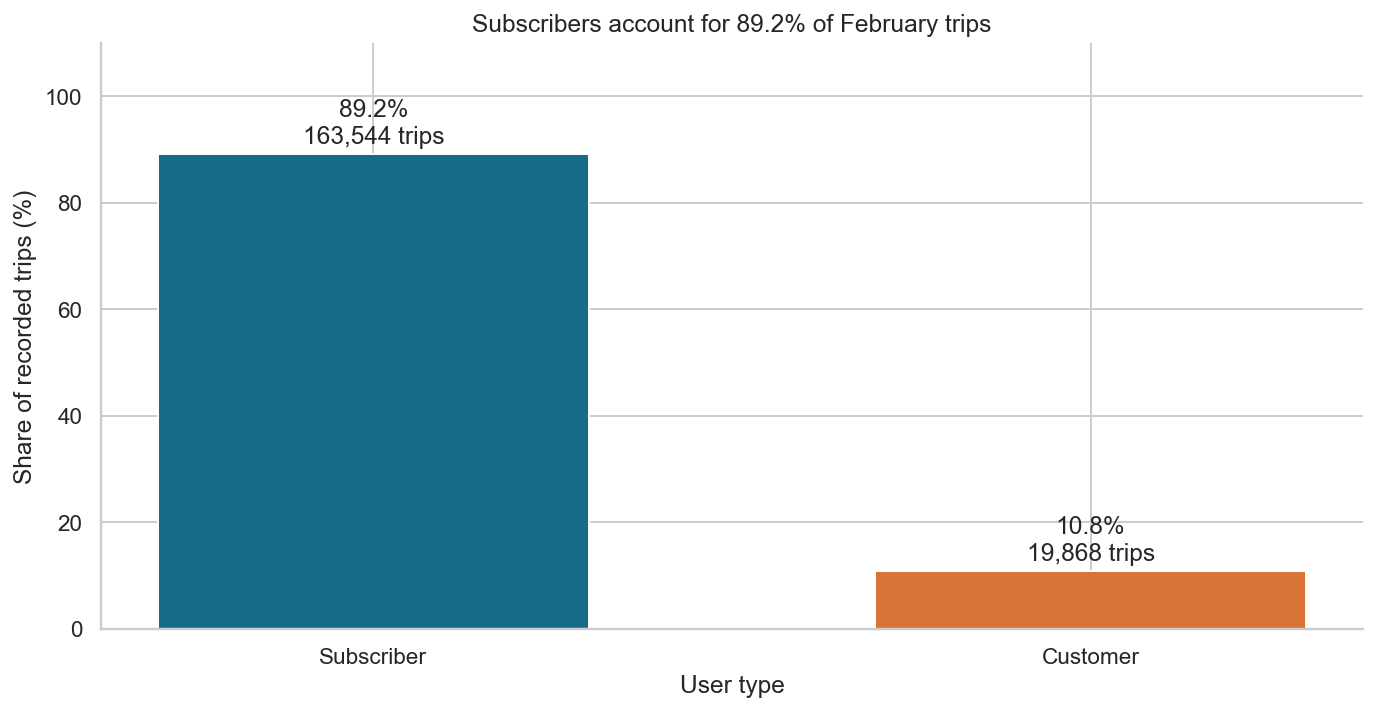

In [3]:
fig = explanatory_figure('e_composition', trips)
show_chart(fig, 'ii_e_composition')

**Observations.** Subscriber trips account for 89.2% of February records, versus 10.8% for Customer trips. Percentages and trip counts are annotated to establish the scale imbalance; they describe trip categories rather than distinct people.

### Question — Do weekday timing patterns differ after adjusting for group size?

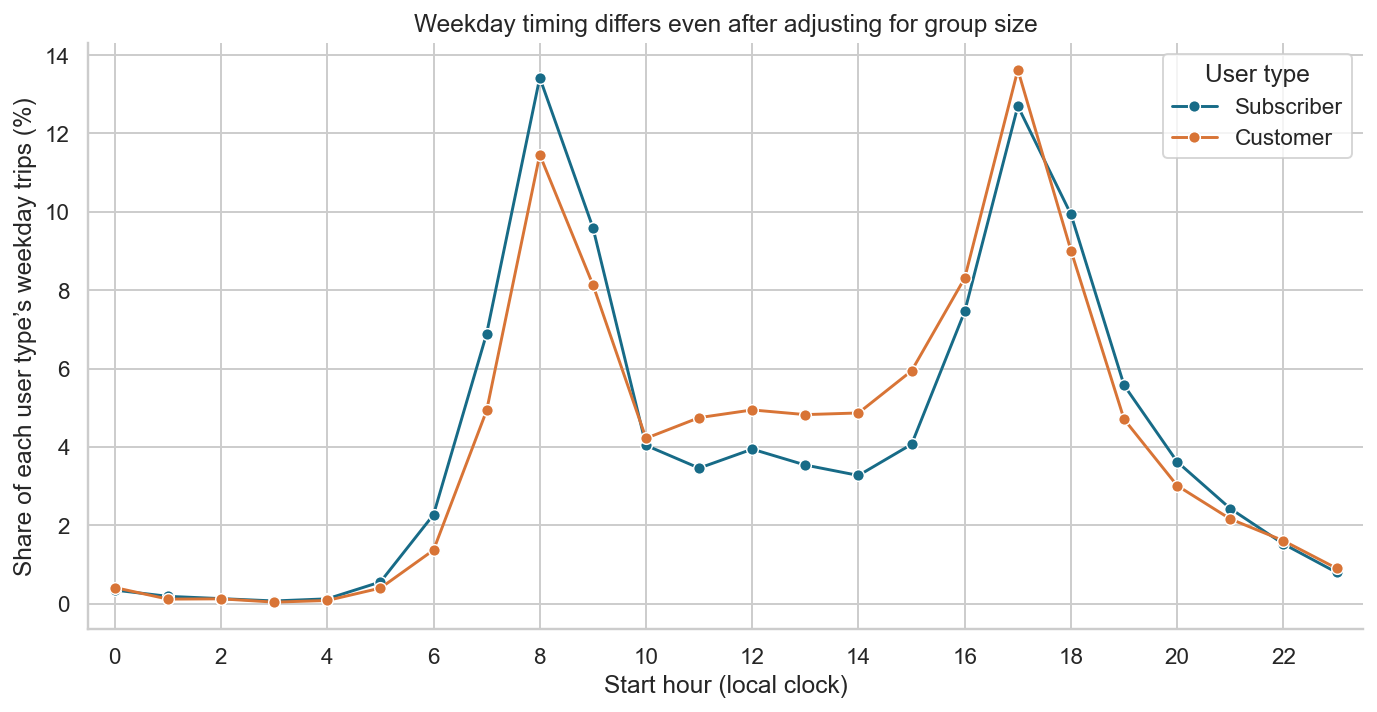

In [4]:
fig = explanatory_figure('e_weekday_profile', trips)
show_chart(fig, 'ii_e_weekday_profile')

**Observations.** Each line divides hourly weekday trips by all weekday trips within its user type, removing the dominance of the larger Subscriber group from the timing comparison. Subscriber trips show pronounced morning and late-afternoon concentrations; Customer trips peak at 17:00, but trip purpose is not recorded.

### Question — How does typical duration differ by user type?

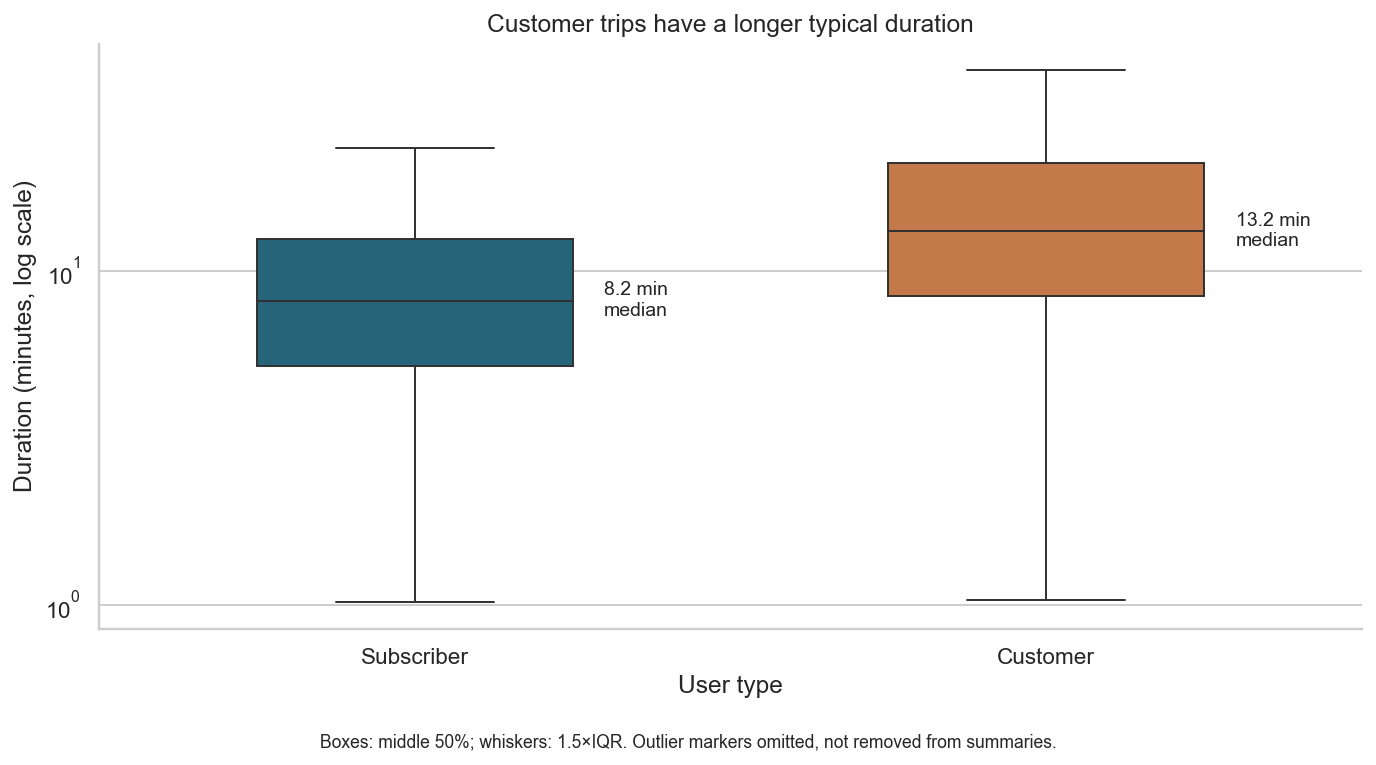

In [5]:
fig = explanatory_figure('e_duration', trips)
show_chart(fig, 'ii_e_duration')

**Observations.** The Customer median is 13.2 minutes, compared with 8.2 minutes for Subscriber trips. Log coordinates make the central distributions readable; omitted outlier markers are a display choice only, and every valid trip contributes to the boxes and medians.

### Question — Does the weekday–weekend volume difference survive exposure adjustment?

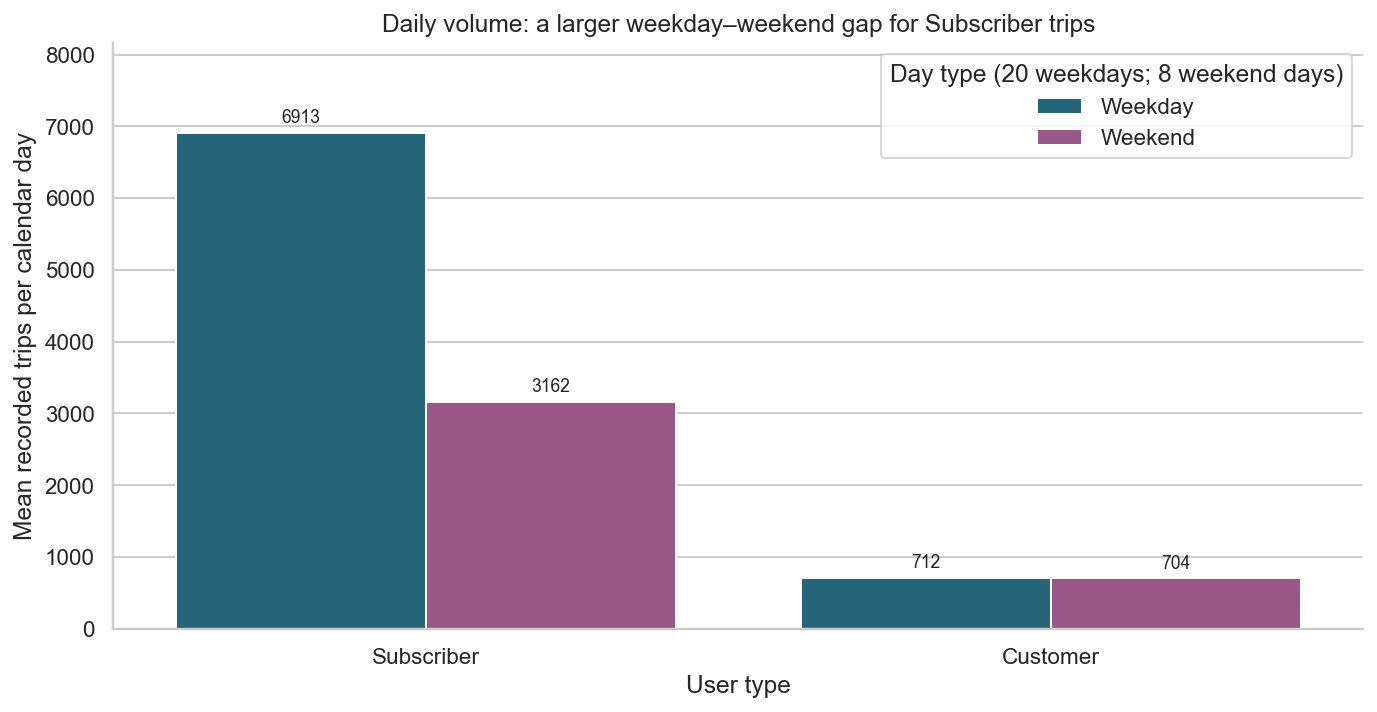

In [6]:
fig = explanatory_figure('e_calendar_rates', trips)
show_chart(fig, 'ii_e_calendar_rates')

**Observations.** Dividing by 20 weekdays and eight weekend days yields about 6,913 versus 3,162 daily Subscriber trips, compared with about 712 versus 704 Customer trips. The larger Subscriber gap is therefore not solely an artifact of more weekdays in the month; these remain recorded trip volumes, not per-person usage rates.

## Takeaways and limits

User-type composition, trip duration and temporal profiles tell complementary stories; no single pooled plot captures all three. All figures use the same valid trip population, consistent colors and explicit denominators. One month cannot establish seasonal demand, unique-rider behavior, causality or the purpose of any trip; a broader study should add time periods and contextual service data.

The accompanying HTML is the presentation report, with plotting code hidden and all figures embedded; the notebook retains the executable source for review.